# 04. FoldedVision AI — 카메라 커버(Lens 파트) 정상/불량 판정 · YOLO26n

**왜 데이터를 바꿨나요?** 공개 VISION Lens에는 정상 렌즈 사진이 0장이었습니다. 팀 라벨 93장도 모두 결함이었어요. 그래서 모델이 정상을 배울 수 없었고, 정상 렌즈도 거의 다 NG로 판정될 것으로 추정됐습니다. 세 부품(Lens·Ring·PCB) 판정을 합치는 팀 시스템에서는, 이 상태로는 모든 모듈이 NG가 됩니다.

그래서 Lens 파트는 **3CAD의 알루미늄 카메라 커버**(Aluminum_Camera_Cover)로 정상/불량을 판정합니다.
- 카메라 렌즈 앞을 덮는 부품입니다.
- 실제 3C 제품 생산라인에서 찍은 사진입니다.
- **정상 사진과 불량 사진이 모두 있어서** 정상 오검출률을 실제로 측정할 수 있습니다.

| 단계 | 내용 |
|---|---|
| 1. 데이터 | 3CAD 압축 파일을 찾거나 받고, **카메라 커버 폴더만** 풉니다 |
| 2. 점검 | 정상/불량 사진 수, 결함 종류, 마스크, 중복 사진을 확인합니다 |
| 3. 분할 | 정상·불량·결함 종류 비율을 유지하며 학습 60% / 검증 20% / 평가 20%로 나눕니다(중복 사진은 같은 쪽) |
| 4. YOLO 데이터 | 결함 마스크 → 결함 상자. 정상 사진은 상자 없음 |
| 5. 학습 | `yolo26n.pt`(팀 공통)에서 이어서 학습합니다. 저장 모델이 있으면 재사용합니다 |
| 6. 판정 | 사진 점수 = 가장 높은 상자 신뢰도. 경계는 **검증 사진으로만** 정합니다 → OK / REVIEW / NG |
| 7. 평가 | 평가 사진(정상+불량)에서 불량 검출률, **정상 오검출률**, 혼동행렬, 결함 종류별 성능 |
| 8. 통합 | 팀 공통 CSV/JSON, `predict_part(image)`, 모듈 통합 판정 함수 |

**준비:** PyCharm 터미널(`.venv` 켜진 상태)에서 한 번만 실행하세요.
```
pip install ultralytics gdown
```

> **데이터 출처와 사용 조건:** 3CAD(AAAI 2025, Yang 외)입니다. 정식 라이선스가 명시되지 않아 **비상업 교육용**으로만 쓰고 출처를 표기합니다. 원본 사진은 다시 배포하지 않습니다. 공개 데이터 PoC이며, 자화전자 실제 생산라인 성능이 아닙니다.

In [1]:
# ── PART 01. 실행 설정 ──
from pathlib import Path
import os
NOTEBOOK_ID = "04"
PART_TYPE = "CameraCover"  # 팀 통합 파일의 part_type (팀에서 "Lens"로 맞추기로 했다면 바꾸세요)
CATEGORY = "Aluminum_Camera_Cover"
SEED = 42
RUN_MODE = os.environ.get("FOLDEDVISION_MODE", "full")  # "quick" 또는 "full"
assert RUN_MODE in ("quick", "full")
QUICK = RUN_MODE == "quick"
USE_SAVED_MODELS = True

# 데이터 받기: 원작자 Google Drive 파일(3CAD 전체, 영어 결함 이름판)
GDRIVE_FILE_ID = "1BIX0H8TZp0wmrAnXPw8_aCAIX1j1Fzwz"
ALLOW_DOWNLOAD = True  # 압축 파일이 없으면 gdown으로 받습니다(용량이 크니 디스크 여유 확인)

SPLIT_FRACTIONS = (0.6, 0.2, 0.2)  # 학습 / 검증 / 평가
QUICK_LIMIT = 60  # quick 모드: 정상·불량 각각 최대 장수
YOLO_MODEL = "yolo26n.pt"
YOLO_IMGSZ = 640
YOLO_EPOCHS = 2 if QUICK else 40
YOLO_PATIENCE = 10
YOLO_BATCH = 8
YOLO_DEVICE = "cpu"
MIN_MASK_BLOB_PX = 4  # 마스크에서 이보다 작은 점은 상자로 만들지 않음
NG_RECALL_TARGET = 0.95  # NG 경계: 검증 불량 사진 Recall 95% 이상 중 Precision 최대
OK_RECALL_TARGET = 0.99  # OK 상한: 검증 불량 사진 Recall 99% → 사이 구간이 REVIEW
ENABLE_GRADIO = False  # True: 로컬 127.0.0.1:7864 검사 화면
MODEL_VERSION_TAG = "v1"

In [2]:
# 경로와 공통 도구
import sys, json, shutil, hashlib, time, platform, zipfile, tarfile, re
from collections import Counter
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, accuracy_score,
                             precision_recall_curve, roc_curve)
KST = timezone(timedelta(hours=9))
plt.rcParams["font.family"] = "Malgun Gothic" if platform.system() == "Windows" else "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd().resolve()
DATA_ROOT = ROOT / "data" / "3CAD"
ARCHIVE_DIR = ROOT / "data" / "archives"
PROCESSED = ROOT / "data" / "processed" / "camera_cover"
MODEL_DIR = ROOT / ("models/quick" if QUICK else "models")
OUT_DIR = ROOT / ("outputs/quick" if QUICK else "outputs")
FIG_DIR, MET_DIR, INTEG_DIR = OUT_DIR / "figures", OUT_DIR / "metrics", OUT_DIR / "integration"
for folder in [DATA_ROOT, ARCHIVE_DIR, PROCESSED, MODEL_DIR, FIG_DIR, MET_DIR, INTEG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
IMAGE_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_rgb(path):
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"이미지 읽기 실패: {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def read_gray(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
print("실행 모드:", RUN_MODE, "/ 데이터:", DATA_ROOT, "/ 모델:", MODEL_DIR)

실행 모드: full / 데이터: C:\Project\Ai_Source\FoldedVision_Lens\data\3CAD / 모델: C:\Project\Ai_Source\FoldedVision_Lens\models


## PART 02. 데이터 준비 — 카메라 커버 폴더만 풀기
아래 순서대로 찾고, 앞 단계에서 찾으면 뒤 단계는 건너뜁니다.
1. `data/3CAD/` 아래에 이미 `Aluminum_Camera_Cover` 폴더가 있으면 그대로 씁니다.
2. `data/archives/`에 3CAD 압축 파일(zip/tar)이 있으면 **카메라 커버 폴더만** 풉니다. 브라우저로 직접 받은 파일을 여기에 넣어도 됩니다.
3. 둘 다 없으면 원작자 Google Drive 파일을 `gdown`으로 받아 같은 방식으로 풉니다. 압축 파일은 3CAD 전체라 큽니다. 풀고 나면 지워도 됩니다.

- 안전하게 풉니다: 폴더 밖으로 나가는 경로(`..`)나 절대 경로는 건너뜁니다.
- rar/7z 형식이면 자동으로 풀 수 없습니다. 반디집 등으로 카메라 커버 폴더만 `data/3CAD/`에 풀어 주세요.

In [3]:
# 카메라 커버 폴더 찾기 → 압축에서 해당 폴더만 풀기 → 없으면 원작자 Drive에서 받기
def find_category_dir():
    hits = [p for p in DATA_ROOT.rglob(CATEGORY) if p.is_dir()]
    return min(hits, key=lambda p: len(p.parts)) if hits else None

def safe_member(name):
    parts = Path(name.replace("\\", "/")).parts
    return not (name.startswith(("/", "\\")) or re.match(r"^[A-Za-z]:", name) or ".." in parts)

def extract_category(archive):
    count = 0
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:
            for info in z.infolist():
                if f"{CATEGORY}/" in info.filename.replace("\\", "/") and safe_member(info.filename) and not info.is_dir():
                    target = DATA_ROOT / info.filename
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with z.open(info) as src, open(target, "wb") as dst:
                        shutil.copyfileobj(src, dst)
                    count += 1
    elif tarfile.is_tarfile(archive):
        with tarfile.open(archive) as t:
            for member in t.getmembers():
                if f"{CATEGORY}/" in member.name and member.isfile() and safe_member(member.name):
                    target = DATA_ROOT / member.name
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with t.extractfile(member) as src, open(target, "wb") as dst:
                        shutil.copyfileobj(src, dst)
                    count += 1
    else:
        print(f"zip/tar가 아니라 자동으로 풀 수 없습니다: {archive.name} → 직접 풀어 {CATEGORY} 폴더를 {DATA_ROOT}에 넣어 주세요.")
    return count

category_dir = find_category_dir()
if category_dir is None:
    archives = [p for p in ARCHIVE_DIR.iterdir() if p.is_file() and p.suffix.lower() in {".zip", ".tar", ".gz", ".tgz"} and "3cad" in p.name.lower()]
    if not archives and ALLOW_DOWNLOAD:
        try:
            import gdown
        except ImportError:
            raise ImportError("gdown이 없습니다. 터미널에서 'pip install gdown' 실행 후 이 셀을 다시 실행하세요.")
        target = ARCHIVE_DIR / "3CAD.zip"
        print("3CAD 압축 파일 받는 중(전체 데이터라 오래 걸릴 수 있음) →", target)
        gdown.download(id=GDRIVE_FILE_ID, output=str(target), quiet=False)
        archives = [target] if target.exists() and target.stat().st_size > 0 else []
    for archive in archives:
        print(archive.name, "→ 카메라 커버 파일", extract_category(archive), "개 풂")
    category_dir = find_category_dir()
if category_dir is None:
    raise FileNotFoundError(f"{CATEGORY} 폴더를 찾지 못했습니다. 3CAD 압축 파일을 {ARCHIVE_DIR}에 넣거나 직접 풀어 {DATA_ROOT}에 두세요.")
print("카메라 커버 폴더:", category_dir)
for sub in sorted(p for p in category_dir.rglob("*") if p.is_dir()):
    n = sum(1 for f in sub.iterdir() if f.suffix.lower() in IMAGE_EXT)
    if n:
        print(f"  {sub.relative_to(category_dir)}: {n}장")

3CAD.zip → 카메라 커버 파일 3307 개 풂
카메라 커버 폴더: C:\Project\Ai_Source\FoldedVision_Lens\data\3CAD\3CAD\Aluminum_Camera_Cover
  ground_truth\bright shadow: 58장
  ground_truth\bruise: 225장
  ground_truth\bump: 15장
  ground_truth\deformation: 40장
  ground_truth\discoloration: 54장
  ground_truth\overwashing: 75장
  ground_truth\scratche: 330장
  ground_truth\uneven: 80장
  ground_truth\watermark: 92장
  ground_truth\whitening: 108장
  test\bright shadow: 58장
  test\bruise: 225장
  test\bump: 15장
  test\deformation: 40장
  test\discoloration: 54장
  test\good: 369장
  test\overwashing: 75장
  test\scratche: 330장
  test\uneven: 80장
  test\watermark: 92장
  test\whitening: 108장
  train\good: 784장


## PART 03. 데이터 점검
- 폴더 이름으로 정답을 정합니다. `good`이면 정상(0), 그 밖의 결함 종류 폴더면 불량(1)입니다.
- 마스크(`ground_truth`)를 사진과 짝지어, 불량 사진마다 결함 영역이 있는지 확인합니다.
- 내용이 완전히 같은 사진(파일 지문이 같음)을 찾습니다. 같은 사진이 학습과 평가에 나뉘면 성능이 부풀려지기 때문입니다.
- 3CAD 원래 구성(학습=정상만, 평가=정상+불량)은 **비지도 이상탐지용**입니다. 이 노트북은 YOLO **지도 학습**이라 정상·불량을 모두 모아 다시 나눕니다.

In [4]:
# 사진·정답·마스크 목록 만들기
MASK_FOLDER_NAMES = {"ground_truth", "groundtruth", "gt", "mask", "masks"}
files = [p for p in category_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXT]
is_mask_file = lambda p: any(part.lower() in MASK_FOLDER_NAMES for part in p.relative_to(category_dir).parts)
mask_index = {}
for p in files:
    if is_mask_file(p):
        stem = re.sub(r"(_mask|_gt|_label)$", "", p.stem, flags=re.I)
        mask_index[(p.parent.name, stem)] = p
        mask_index.setdefault(("*", stem), p)
rows = []
for p in files:
    if is_mask_file(p):
        continue
    parts = [x.lower() for x in p.relative_to(category_dir).parts]
    defect_type = p.parent.name
    label = 0 if defect_type.lower() in {"good", "ok", "normal"} else 1
    mask = mask_index.get((defect_type, p.stem)) or (mask_index.get(("*", p.stem)) if label else None)
    rows.append({"image_key": str(p.relative_to(category_dir)).replace("\\", "/"), "path": str(p.relative_to(ROOT)), "official_split": "train" if "train" in parts else ("test" if "test" in parts else "other"),
                 "defect_type": "good" if label == 0 else defect_type, "label": label, "mask_path": str(mask.relative_to(ROOT)) if mask is not None else "",
                 "sha256": sha256_file(p)})
cc = pd.DataFrame(rows).sort_values("image_key").reset_index(drop=True)
dup = cc.groupby("sha256").label.nunique()
conflict = int((dup > 1).sum())
cc = cc[~cc.sha256.isin(dup[dup > 1].index)].reset_index(drop=True)  # 같은 사진이 정상·불량에 동시에 있으면 정답이 모순 → 제외
if QUICK:
    cc = pd.concat([part.sample(n=min(len(part), QUICK_LIMIT), random_state=SEED) for _, part in cc.groupby("label")]).sort_values("image_key").reset_index(drop=True)
sizes = [read_gray(ROOT / p).shape for p in cc.path.sample(n=min(len(cc), 50), random_state=SEED)]
audit = {"category": CATEGORY, "images": int(len(cc)), "normal": int((cc.label == 0).sum()), "defect": int((cc.label == 1).sum()),
         "defect_types": cc[cc.label == 1].defect_type.value_counts().to_dict(), "defect_without_mask": int(((cc.label == 1) & (cc.mask_path == "")).sum()),
         "exact_duplicate_groups": int((cc.groupby("sha256").size() > 1).sum()), "label_conflict_duplicates_removed": conflict,
         "official_split": pd.crosstab(cc.official_split, cc.label).to_dict(), "size_sample_hw_min_max": [min(sizes), max(sizes)] if sizes else None}
save_json(PROCESSED / "camera_cover_audit.json", audit)
print(json.dumps(audit, ensure_ascii=False, indent=1))

{
 "category": "Aluminum_Camera_Cover",
 "images": 2230,
 "normal": 1153,
 "defect": 1077,
 "defect_types": {
  "scratche": 330,
  "bruise": 225,
  "whitening": 108,
  "watermark": 92,
  "uneven": 80,
  "overwashing": 75,
  "bright shadow": 58,
  "discoloration": 54,
  "deformation": 40,
  "bump": 15
 },
 "defect_without_mask": 0,
 "exact_duplicate_groups": 10,
 "label_conflict_duplicates_removed": 0,
 "official_split": {
  "0": {
   "test": 369,
   "train": 784
  },
  "1": {
   "test": 1077,
   "train": 0
  }
 },
 "size_sample_hw_min_max": [
  [
   288,
   448
  ],
  [
   1024,
   1024
  ]
 ]
}


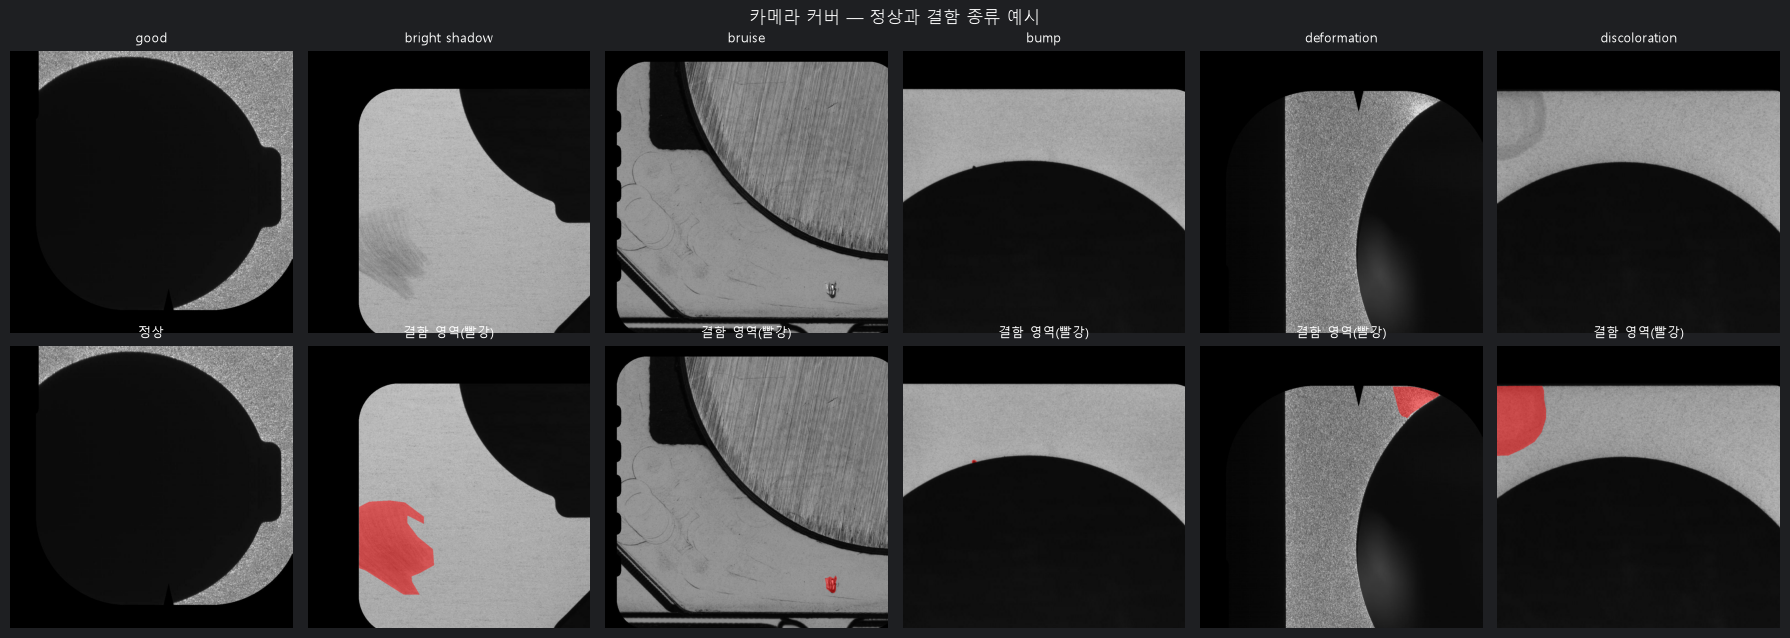

In [5]:
# 정상·결함 예시 그림
types = ["good"] + sorted(cc[cc.label == 1].defect_type.unique())
fig, axes = plt.subplots(2, min(6, len(types)), figsize=(3 * min(6, len(types)), 6.5))
axes = np.atleast_2d(axes)
for j, t in enumerate(types[: axes.shape[1]]):
    pick = cc[cc.defect_type == t].sample(n=1, random_state=SEED).iloc[0]
    image = read_rgb(ROOT / pick.path)
    axes[0, j].imshow(image)
    axes[0, j].set_title(t, fontsize=9)
    overlay = image.copy()
    if pick.mask_path:
        m = read_gray(ROOT / pick.mask_path)
        m = cv2.resize(m, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
        overlay[m] = (0.5 * overlay[m] + [127, 0, 0]).astype(np.uint8)
    axes[1, j].imshow(overlay)
    axes[1, j].set_title("결함 영역(빨강)" if pick.mask_path else "정상", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("카메라 커버 — 정상과 결함 종류 예시")
fig.tight_layout()
fig.savefig(FIG_DIR / "cc_examples.png", dpi=120)
plt.show()

## PART 04. 학습 / 검증 / 평가 나누기
- 정상과 결함 종류별로 비율을 유지하며 60 / 20 / 20으로 나눕니다(층화 분할).
- 내용이 같은 사진은 **같은 쪽에만** 들어가게 묶어서 나눕니다.
- 경계(OK / REVIEW / NG)는 **검증**으로만 정하고, **평가**는 마지막에 한 번만 채점합니다.

In [6]:
# 중복 사진 묶음 단위 층화 분할
rng = np.random.default_rng(SEED)
groups = cc.groupby("sha256").agg(defect_type=("defect_type", "first")).reset_index()
assign = {}
for t, part in groups.groupby("defect_type"):
    order = part.sha256.to_numpy()[rng.permutation(len(part))]
    n_train, n_val = round(SPLIT_FRACTIONS[0] * len(order)), round(SPLIT_FRACTIONS[1] * len(order))
    for i, h in enumerate(order):
        assign[h] = "train" if i < n_train else ("validation" if i < n_train + n_val else "test")
cc["split"] = cc.sha256.map(assign)
assert (cc.groupby("sha256").split.nunique() == 1).all()
SPLIT_SIGNATURE = hashlib.sha256(json.dumps(sorted(zip(cc.image_key, cc.split, cc.sha256))).encode()).hexdigest()
cc.to_csv(PROCESSED / "camera_cover_split.csv", index=False, encoding="utf-8-sig")
print(pd.crosstab(cc.defect_type, cc.split, margins=True))

split          test  train  validation   All
defect_type                                 
bright shadow    11     35          12    58
bruise           45    135          45   225
bump              3      9           3    15
deformation       8     24           8    40
discoloration    11     32          11    54
good            233    683         237  1153
overwashing      15     45          15    75
scratche         66    198          66   330
uneven           16     48          16    80
watermark        19     55          18    92
whitening        21     65          22   108
All             448   1329         453  2230


## PART 05. YOLO 형식 데이터
- 불량 사진: 마스크의 결함 덩어리마다 상자 1개를 만듭니다. 클래스는 결함 종류이고, 4픽셀 미만 점은 뺍니다.
- 정상 사진: 상자 없는 빈 정답 파일을 만듭니다. YOLO가 "결함 없음"을 배우는 데 씁니다.
- 마스크가 없는 불량 사진은 상자를 만들 수 없어 **YOLO 학습에서만 빼고**, 사진 단위 평가에는 그대로 씁니다.
- 사진은 원본 그대로 복사합니다. 크기 조정은 YOLO가 640으로 합니다.

In [7]:
# 마스크 → 상자 → YOLO 데이터셋 (설정이 같으면 재사용)
CC_CLASSES = sorted(cc[cc.label == 1].defect_type.unique())
YOLO_DATA = ROOT / "data" / ("yolo_cc_quick" if QUICK else "yolo_cc")
YOLO_YAML = YOLO_DATA / "cc.yaml"
FOLDER = {"train": "train", "validation": "val", "test": "test"}
DATA_SIGNATURE = hashlib.sha256(json.dumps({"split": SPLIT_SIGNATURE, "classes": CC_CLASSES, "min_blob": MIN_MASK_BLOB_PX, "version": "cc-yolo-data-1"}).encode()).hexdigest()

def mask_boxes(mask_path, shape):
    m = read_gray(ROOT / mask_path)
    if m.shape[:2] != shape[:2]:
        m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    n, _, stats, _ = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=8)
    return [(int(x), int(y), int(x + w), int(y + h)) for x, y, w, h, a in stats[1:] if a >= MIN_MASK_BLOB_PX]

sig_file = YOLO_DATA / "signature.json"
if sig_file.exists() and json.loads(sig_file.read_text(encoding="utf-8")).get("signature") == DATA_SIGNATURE:
    yolo_index = pd.read_csv(YOLO_DATA / "index.csv")
    print("YOLO 데이터셋 → 기존 데이터 재사용")
else:
    if YOLO_DATA.exists():
        shutil.rmtree(YOLO_DATA)
    records = []
    for r in cc.itertuples():
        if r.label == 1 and not r.mask_path:
            continue
        folder = FOLDER[r.split]
        (YOLO_DATA / "images" / folder).mkdir(parents=True, exist_ok=True)
        (YOLO_DATA / "labels" / folder).mkdir(parents=True, exist_ok=True)
        name = re.sub(r"[^0-9A-Za-z_-]", "_", r.image_key.rsplit(".", 1)[0])
        src = ROOT / r.path
        shutil.copy2(src, YOLO_DATA / "images" / folder / f"{name}{src.suffix.lower()}")
        height, width = read_gray(src).shape[:2]
        boxes = mask_boxes(r.mask_path, (height, width)) if r.label == 1 else []
        cls = CC_CLASSES.index(r.defect_type) if r.label == 1 else -1
        lines = [f"{cls} {(x0 + x1) / 2 / width:.6f} {(y0 + y1) / 2 / height:.6f} {(x1 - x0) / width:.6f} {(y1 - y0) / height:.6f}" for x0, y0, x1, y1 in boxes]
        (YOLO_DATA / "labels" / folder / f"{name}.txt").write_text("\n".join(lines), encoding="utf-8")
        records.append({"image_key": r.image_key, "split": r.split, "name": name, "label": r.label, "boxes": len(boxes)})
    yolo_index = pd.DataFrame(records)
    yolo_index.to_csv(YOLO_DATA / "index.csv", index=False, encoding="utf-8-sig")
    names_yaml = "\n".join(f"  {i}: {n}" for i, n in enumerate(CC_CLASSES))
    YOLO_YAML.write_text(f"path: {YOLO_DATA.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n{names_yaml}\n", encoding="utf-8")
    save_json(sig_file, {"signature": DATA_SIGNATURE})
print(pd.crosstab(yolo_index.split, yolo_index.label).rename(columns={0: "정상", 1: "불량"}))
print("불량인데 상자 0개(마스크가 비었음):", int(((yolo_index.label == 1) & (yolo_index.boxes == 0)).sum()), "/ 클래스:", CC_CLASSES)

label        정상   불량
split               
test        233  215
train       683  646
validation  237  216
불량인데 상자 0개(마스크가 비었음): 0 / 클래스: ['bright shadow', 'bruise', 'bump', 'deformation', 'discoloration', 'overwashing', 'scratche', 'uneven', 'watermark', 'whitening']


## PART 06. YOLO26n 학습
- 팀 공통 `yolo26n.pt`(COCO 사전학습)에서 시작해 카메라 커버 사진으로 이어서 학습합니다.
- 검증 mAP가 10 epoch 동안 좋아지지 않으면 멈추고, 가장 좋았던 가중치를 `models/camera_cover_yolo26n.pt`로 저장합니다.
- 위아래·좌우 뒤집기를 켭니다. CPU 학습이라 오래 걸리며, 다음 실행부터는 저장 모델을 다시 씁니다.

Ultralytics 8.4.218  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core Ultra 7 255H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Project\Ai_Source\FoldedVision_Lens\data\yolo_cc\cc.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=camera_cover_yolo26n, nbs=64, 

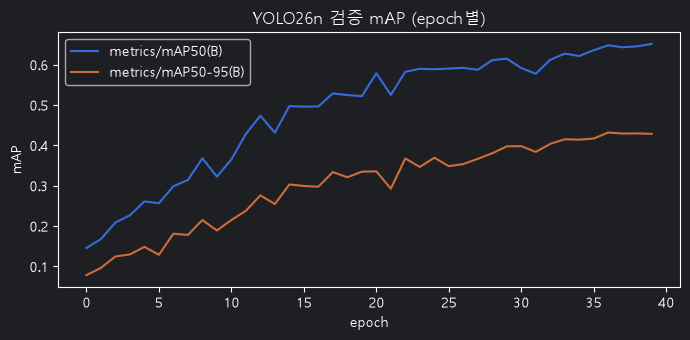

In [8]:
# [YOLO] 학습 (저장 모델 재사용)
from ultralytics import YOLO
YOLO_RUNS = MODEL_DIR / "yolo_runs"
YOLO_BEST = MODEL_DIR / "camera_cover_yolo26n.pt"
YOLO_META = MODEL_DIR / "camera_cover_yolo26n.json"
model_signature = hashlib.sha256(json.dumps({"data": DATA_SIGNATURE, "model": YOLO_MODEL, "epochs": YOLO_EPOCHS, "imgsz": YOLO_IMGSZ, "batch": YOLO_BATCH,
                                             "patience": YOLO_PATIENCE, "seed": SEED, "version": "cc-yolo-1"}).encode()).hexdigest()
if USE_SAVED_MODELS and YOLO_BEST.exists() and YOLO_META.exists() and json.loads(YOLO_META.read_text(encoding="utf-8")).get("signature") == model_signature:
    yolo_meta = json.loads(YOLO_META.read_text(encoding="utf-8"))
    print("camera_cover_yolo26n → 데이터·설정이 같은 저장 모델 재사용")
else:
    trainer_model = YOLO(YOLO_MODEL)
    started = time.perf_counter()
    trainer_model.train(data=str(YOLO_YAML), epochs=YOLO_EPOCHS, patience=YOLO_PATIENCE, imgsz=YOLO_IMGSZ, batch=YOLO_BATCH, device=YOLO_DEVICE, workers=0,
                        seed=SEED, deterministic=True, project=str(YOLO_RUNS), name="camera_cover_yolo26n", exist_ok=True, flipud=0.5, fliplr=0.5, plots=True, verbose=False)
    save_dir = Path(trainer_model.trainer.save_dir)
    shutil.copy2(save_dir / "weights" / "best.pt", YOLO_BEST)
    history = save_dir / "results.csv"
    if history.exists():
        shutil.copy2(history, MET_DIR / "camera_cover_yolo26n_history.csv")
    yolo_meta = {"signature": model_signature, "training_seconds": time.perf_counter() - started,
                 "epochs_completed": int(len(pd.read_csv(history))) if history.exists() else None, "run_dir": str(save_dir)}
    save_json(YOLO_META, yolo_meta)
yolo = YOLO(str(YOLO_BEST))
MODEL_SHA = sha256_file(YOLO_BEST)
MODEL_VERSION = f"camera_cover_yolo26n-{MODEL_VERSION_TAG}-{MODEL_SHA[:8]}"
print({k: v for k, v in yolo_meta.items() if k != "signature"}, "/ 버전:", MODEL_VERSION)
hist_file = MET_DIR / "camera_cover_yolo26n_history.csv"
if hist_file.exists():
    hist = pd.read_csv(hist_file)
    hist.columns = [c.strip() for c in hist.columns]
    cols = [c for c in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"] if c in hist]
    if cols:
        ax = hist[cols].plot(figsize=(7, 3.5), title="YOLO26n 검증 mAP (epoch별)")
        ax.set(xlabel="epoch", ylabel="mAP")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "cc_training_curve.png", dpi=130)
        plt.show()

## PART 07. 사진 단위 정상/불량 판정과 평가
- **사진 점수** = 그 사진에서 YOLO가 찾은 결함 상자 신뢰도의 최댓값입니다. 상자가 없으면 0입니다.
- **경계는 검증 사진으로만** 정합니다.
  - NG 경계: 검증 불량 사진 Recall 95% 이상 중 Precision 최대
  - OK 상한: 검증 불량 사진 Recall 99%
  - 그 사이 점수는 REVIEW(사람 재검)
- **평가 사진은 정상과 불량이 모두 있어서** 불량 검출률과 **정상 오검출률**을 실제로 측정합니다.

{
 "threshold_ng": 0.02060859464108944,
 "threshold_ok_upper": 0.0038509017322212458,
 "test_images": 448,
 "test_normal": 233,
 "test_defect": 215,
 "accuracy": 0.90625,
 "precision": 0.8744588744588745,
 "recall": 0.9395348837209302,
 "f1": 0.905829596412556,
 "roc_auc": 0.9583790797484778,
 "average_precision": 0.9579407089329299,
 "TP": 202,
 "FP": 29,
 "TN": 204,
 "FN": 13,
 "false_positive_rate": 0.12446351931330472,
 "normal_review_rate": 0.38197424892703863,
 "defect_passed_as_ok": 4,
 "defect_not_ok_rate": 0.9813953488372092,
 "review_rate": 0.21875,
 "inference_ms_per_image_cpu": 42.29288257489996
}
decision   OK  REVIEW   NG
label                     
불량          4       9  202
정상        115      89   29
               사진 수  자동 NG 비율  OK로 통과
defect_type                          
bright shadow  11.0     0.909     1.0
bruise         45.0     1.000     0.0
bump            3.0     1.000     0.0
deformation     8.0     0.375     0.0
discoloration  11.0     0.909     1.0
overwashi

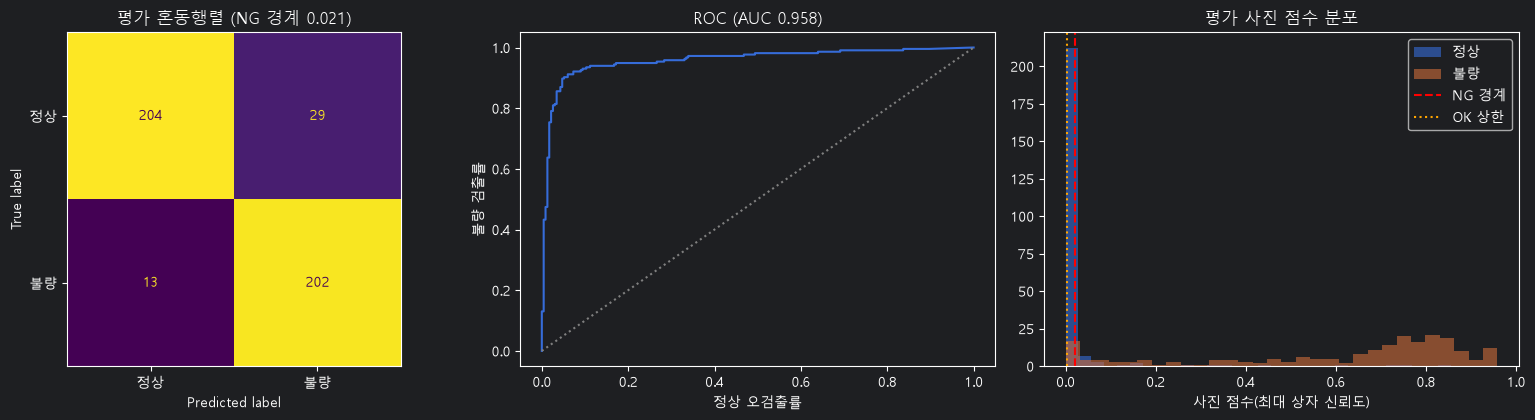

In [9]:
# [YOLO] 검증·평가 사진 점수 → 경계 → 평가
def detect(rgb, conf=0.001):
    result = yolo.predict([cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)], imgsz=YOLO_IMGSZ, conf=conf, device=YOLO_DEVICE, verbose=False)[0]
    if result.boxes is None or len(result.boxes) == 0:
        return np.zeros((0, 6), np.float32)
    return np.column_stack([result.boxes.xyxy.cpu().numpy(), result.boxes.conf.cpu().numpy(), result.boxes.cls.cpu().numpy()]).astype(np.float32)

def class_name(c):
    c = int(c)
    return CC_CLASSES[c] if 0 <= c < len(CC_CLASSES) else f"class{c}"

def decide(score, ok_upper, ng):
    return "NG" if score >= ng else ("OK" if score < ok_upper else "REVIEW")

def threshold_for_recall(y, s, target):
    best = None
    for t in np.unique(s):
        p = s >= t
        if recall_score(y, p, zero_division=0) >= target:
            cand = (precision_score(y, p, zero_division=0), float(t))
            best = cand if best is None or cand > best else best
    return best[1] if best else float(s.min())

DETECTIONS, started = {}, time.perf_counter()
for r in cc[cc.split.isin(["validation", "test"])].itertuples():
    DETECTIONS[r.image_key] = detect(read_rgb(ROOT / r.path))
ms_per_image = 1000 * (time.perf_counter() - started) / max(1, len(DETECTIONS))
cc["score"] = cc.image_key.map(lambda k: float(DETECTIONS[k][:, 4].max()) if k in DETECTIONS and len(DETECTIONS[k]) else 0.0)
val, test = cc[cc.split == "validation"], cc[cc.split == "test"].copy()
NG = threshold_for_recall(val.label.to_numpy(), val.score.to_numpy(), NG_RECALL_TARGET)
OK_UPPER = min(NG, threshold_for_recall(val.label.to_numpy(), val.score.to_numpy(), OK_RECALL_TARGET))
test["decision"] = [decide(s, OK_UPPER, NG) for s in test.score]
y, s, pred = test.label.to_numpy(), test.score.to_numpy(), (test.score.to_numpy() >= NG).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
metrics = {"threshold_ng": NG, "threshold_ok_upper": OK_UPPER, "test_images": int(len(test)), "test_normal": int((y == 0).sum()), "test_defect": int((y == 1).sum()),
           "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
           "f1": f1_score(y, pred, zero_division=0), "roc_auc": roc_auc_score(y, s) if len(set(y)) == 2 else None,
           "average_precision": average_precision_score(y, s) if len(set(y)) == 2 else None, "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
           "false_positive_rate": fp / max(1, fp + tn), "normal_review_rate": float((test[test.label == 0].decision == "REVIEW").mean()),
           "defect_passed_as_ok": int(((test.label == 1) & (test.decision == "OK")).sum()), "defect_not_ok_rate": float((test[test.label == 1].decision != "OK").mean()),
           "review_rate": float((test.decision == "REVIEW").mean()), "inference_ms_per_image_cpu": ms_per_image}
print(json.dumps(metrics, ensure_ascii=False, indent=1, default=float))
print(pd.crosstab(test.label.map({0: "정상", 1: "불량"}), test.decision).reindex(columns=["OK", "REVIEW", "NG"], fill_value=0))
by_type = test[test.label == 1].groupby("defect_type").apply(lambda g: pd.Series({"사진 수": len(g), "자동 NG 비율": (g.decision == "NG").mean(), "OK로 통과": int((g.decision == "OK").sum())}), include_groups=False)
print(by_type.round(3))
by_type.to_csv(MET_DIR / "camera_cover_by_defect_type.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ConfusionMatrixDisplay = __import__("sklearn.metrics", fromlist=["ConfusionMatrixDisplay"]).ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=[0, 1]), display_labels=["정상", "불량"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"평가 혼동행렬 (NG 경계 {NG:.3f})")
fpr_curve, tpr_curve, _ = roc_curve(y, s)
axes[1].plot(fpr_curve, tpr_curve)
axes[1].plot([0, 1], [0, 1], ls=":", color="gray")
axes[1].set(title=f"ROC (AUC {metrics['roc_auc']:.3f})", xlabel="정상 오검출률", ylabel="불량 검출률")
for lab, name in [(0, "정상"), (1, "불량")]:
    axes[2].hist(test[test.label == lab].score, bins=30, alpha=0.6, label=name)
axes[2].axvline(NG, color="red", ls="--", label="NG 경계")
axes[2].axvline(OK_UPPER, color="orange", ls=":", label="OK 상한")
axes[2].set(title="평가 사진 점수 분포", xlabel="사진 점수(최대 상자 신뢰도)")
axes[2].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "cc_test_evaluation.png", dpi=130)
plt.show()

Ultralytics 8.4.218  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core Ultra 7 255H)
YOLO26n summary (fused): 121 layers, 2,391,922 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 402.7±292.9 MB/s, size: 59.9 KB)
val: Scanning C:\Project\Ai_Source\FoldedVision_Lens\data\yolo_cc\labels\test... 448 images, 233 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 448/448 2.7Kit/s 0.2s0.3s
val: New cache created: C:\Project\Ai_Source\FoldedVision_Lens\data\yolo_cc\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 3.4it/s 16.6s0.3s
                   all        448        252      0.767      0.635       0.69      0.428
Speed: 1.4ms preprocess, 29.1ms inference, 0.0ms loss, 0.4ms postprocess per image
{
 "mAP50": 0.6902669576443949,
 "mAP50-95": 0.4282678340814202,
 "box_precision": 0.7668114911713357,
 "box_recall": 0.6351212583778262,
 "AP50_by_type": {
  "bright shadow": 0.770431372549

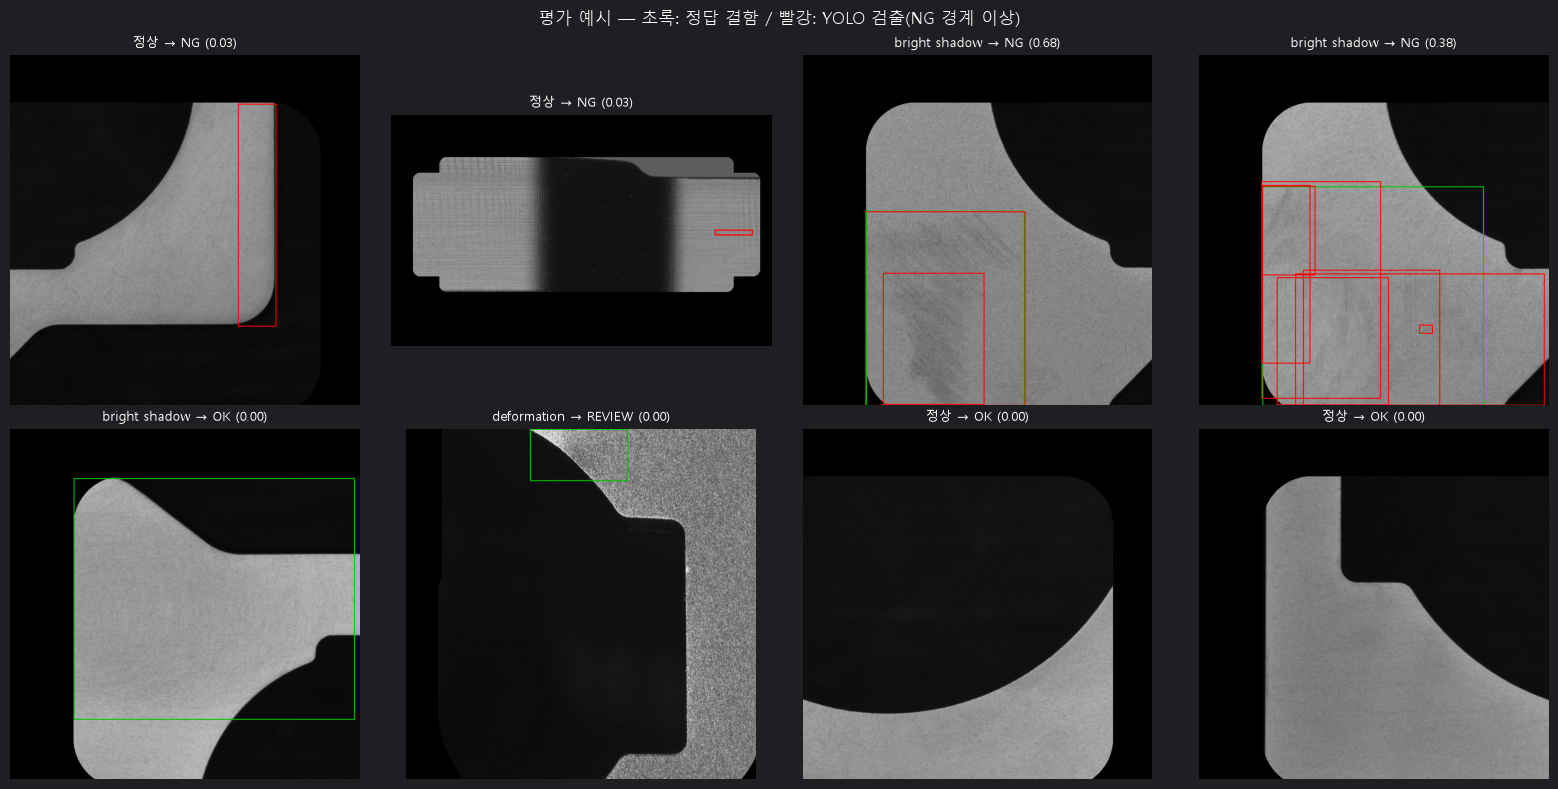

In [10]:
# [YOLO] 표준 검출 지표(mAP)와 검출 예시
det = yolo.val(data=str(YOLO_YAML), split="test", imgsz=YOLO_IMGSZ, batch=YOLO_BATCH, device=YOLO_DEVICE, workers=0, plots=False, verbose=False,
               project=str(YOLO_RUNS), name="eval_test", exist_ok=True)
detection = {"mAP50": float(det.box.map50), "mAP50-95": float(det.box.map), "box_precision": float(det.box.mp), "box_recall": float(det.box.mr)}
try:
    detection["AP50_by_type"] = {class_name(c): float(det.box.ap50[i]) for i, c in enumerate(det.box.ap_class_index)}
except Exception as error:
    detection["AP50_by_type"] = f"읽지 못함: {error}"
print(json.dumps(detection, ensure_ascii=False, indent=1))

picks = pd.concat([test[(test.label == 0) & (test.decision == "NG")].head(2), test[(test.label == 1) & (test.decision == "NG")].head(2),
                   test[(test.label == 1) & (test.decision != "NG")].head(2), test[(test.label == 0) & (test.decision == "OK")].head(2)]).head(8)
if len(picks):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, r in zip(axes.ravel(), picks.itertuples()):
        canvas = read_rgb(ROOT / r.path)
        if r.mask_path:
            for x0, y0, x1, y1 in mask_boxes(r.mask_path, canvas.shape):
                cv2.rectangle(canvas, (x0, y0), (x1, y1), (0, 200, 0), 2)
        for x0, y0, x1, y1, sc, cl in DETECTIONS[r.image_key]:
            if sc >= NG:
                cv2.rectangle(canvas, (int(x0), int(y0)), (int(x1), int(y1)), (255, 0, 0), 2)
        ax.imshow(canvas)
        ax.set_title(f"{'정상' if r.label == 0 else r.defect_type} → {r.decision} ({r.score:.2f})", fontsize=9)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle("평가 예시 — 초록: 정답 결함 / 빨강: YOLO 검출(NG 경계 이상)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "cc_test_examples.png", dpi=120)
    plt.show()

## PART 08. 팀 통합 — `predict_part(image)`와 모듈 판정
- `predict_part(image)`: 사진 한 장 → `{part_type, status, defect_score, threshold, boxes, model_version}`
- `module_decision(parts)`: 세 부품의 판정을 합칩니다. **하나라도 NG면 NG, 하나라도 REVIEW면 REVIEW, 모두 OK면 OK**입니다.
- 결과 파일은 팀 공통 컬럼(`image_id, part_type, split, y_true, defect_score, threshold, y_pred, decision, model_version`)으로 저장합니다.

In [11]:
# 팀 통합 함수와 결과 파일
def predict_part(image):
    started = time.perf_counter()
    image = np.asarray(image)
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    boxes = detect(image[..., :3].astype(np.uint8))
    score = float(boxes[:, 4].max()) if len(boxes) else 0.0
    status = decide(score, OK_UPPER, NG)
    if QUICK:
        status = "REVIEW"
    return {"part_type": PART_TYPE, "status": status, "defect_score": score, "threshold": {"ok_upper": OK_UPPER, "ng": NG}, "model_version": MODEL_VERSION,
            "boxes": [{"class": class_name(c), "confidence": float(sc), "x0": float(x0), "y0": float(y0), "x1": float(x1), "y1": float(y1)}
                      for x0, y0, x1, y1, sc, c in boxes if sc >= NG], "inference_ms": 1000 * (time.perf_counter() - started)}

def module_decision(parts):
    # parts: {"Lens": "OK", "Ring": "NG", "PCB": "REVIEW"} 처럼 부품별 판정
    values = list(parts.values())
    return "NG" if "NG" in values else ("REVIEW" if "REVIEW" in values else "OK")

check = predict_part(read_rgb(ROOT / test.iloc[0].path))
print({k: v for k, v in check.items() if k != "boxes"}, "/ 상자", len(check["boxes"]))
assert module_decision({"Lens": "OK", "Ring": "OK", "PCB": "OK"}) == "OK" and module_decision({"Lens": "OK", "Ring": "REVIEW", "PCB": "OK"}) == "REVIEW"
assert module_decision({"Lens": "NG", "Ring": "OK", "PCB": "REVIEW"}) == "NG"

predictions = pd.DataFrame({"image_id": test.image_key, "part_type": PART_TYPE, "split": "test", "y_true": test.label, "defect_score": test.score,
                            "threshold": NG, "y_pred": (test.score >= NG).astype(int), "decision": test.decision, "model_version": MODEL_VERSION})
predictions.to_csv(INTEG_DIR / "camera_cover_predictions.csv", index=False, encoding="utf-8-sig")
save_json(INTEG_DIR / "camera_cover_metrics.json", {"dataset_name": f"3CAD {CATEGORY}", "part_type": PART_TYPE, "model": "YOLO26n (COCO 사전학습 → 미세조정)",
          "model_version": MODEL_VERSION, "mode": RUN_MODE, "train_count": int((cc.split == "train").sum()), "validation_count": int((cc.split == "validation").sum()),
          "test_count": int(len(test)), **metrics, "detection": detection, "by_defect_type": by_type.reset_index().to_dict("records"),
          "training": {k: v for k, v in yolo_meta.items() if k != "signature"}, "evaluation_note": "3CAD 공개 데이터 PoC. 실제 생산라인 성능 아님."})
save_json(INTEG_DIR / "camera_cover_model_config.json", {"model_path": "models/camera_cover_yolo26n.pt", "model_version": MODEL_VERSION, "base_model": YOLO_MODEL,
          "classes": CC_CLASSES, "input": "RGB 사진(원본 크기) → BGR로 바꿔 YOLO에 전달, imgsz 640", "score": "결함 상자 신뢰도 최댓값(보정된 확률 아님)",
          "threshold": {"ok_upper": OK_UPPER, "ng": NG, "rule": "score≥ng NG, score<ok_upper OK, 그 사이 REVIEW", "basis": "검증 사진 불량 Recall 95%/99%"},
          "module_rule": "부품 중 하나라도 NG→NG, 하나라도 REVIEW→REVIEW, 모두 OK→OK", "dataset_source": "3CAD (AAAI 2025, Yang et al.) — 비상업 교육용, 원본 재배포 안 함"})
print(predictions.groupby(["y_true", "decision"]).size())
print("통합 파일:", sorted(p.name for p in INTEG_DIR.glob("camera_cover_*")))

{'part_type': 'CameraCover', 'status': 'NG', 'defect_score': 0.6777641177177429, 'threshold': {'ok_upper': 0.0038509017322212458, 'ng': 0.02060859464108944}, 'model_version': 'camera_cover_yolo26n-v1-2d8d77ff', 'inference_ms': 67.8715999238193} / 상자 2
y_true  decision
0       NG           29
        OK          115
        REVIEW       89
1       NG          202
        OK            4
        REVIEW        9
dtype: int64
통합 파일: ['camera_cover_metrics.json', 'camera_cover_model_config.json', 'camera_cover_predictions.csv']


In [12]:
# (선택) 검사 화면 — 로컬 127.0.0.1:7864
if ENABLE_GRADIO:
    import gradio as gr
    def ui(image):
        if image is None:
            return "사진을 올려 주세요.", None
        r = predict_part(image)
        canvas = image.copy()
        for b in r["boxes"]:
            cv2.rectangle(canvas, (int(b["x0"]), int(b["y0"])), (int(b["x1"]), int(b["y1"])), (255, 0, 0), 2)
        kinds = Counter(b["class"] for b in r["boxes"])
        return (f"## 판정: {r['status']}\n- 점수 {r['defect_score']:.3f} / OK<{OK_UPPER:.3f}, NG≥{NG:.3f}\n- 검출 결함: {dict(kinds) or '없음'}\n- {r['model_version']} / {r['inference_ms']:.0f} ms"), canvas
    with gr.Blocks(title="카메라 커버 검사") as demo:
        gr.Markdown("### FoldedVision AI — 카메라 커버(Lens 파트) 정상/불량 검사 · YOLO26n")
        upload = gr.Image(type="numpy", label="사진")
        button = gr.Button("검사")
        verdict = gr.Markdown()
        shown = gr.Image(label="검출 결과(빨간 상자)")
        button.click(ui, upload, [verdict, shown])
    demo.launch(share=False, server_name="127.0.0.1", server_port=7864, inbrowser=True)

## 보고서
이번 실행에서 계산된 값만 `outputs/metrics/camera_cover_report.md`에 씁니다.

In [13]:
# 보고서(실측값만)
pct = lambda v: "N/A" if v is None else f"{100 * v:.1f}%"
lines = [f"# 카메라 커버(Lens 파트) 정상/불량 판정 보고 ({RUN_MODE})", "", "> " + ("**quick 모드: 기능 점검용 — 성능으로 쓰지 말 것**" if QUICK else "full 모드 실측") + " / 3CAD 공개 데이터 PoC", "",
         "## 데이터", f"- 3CAD {CATEGORY}: 정상 {audit['normal']}장 / 불량 {audit['defect']}장 / 결함 종류 {len(CC_CLASSES)}개",
         f"- 분할(학습/검증/평가): {int((cc.split == 'train').sum())} / {int((cc.split == 'validation').sum())} / {len(test)}장 (정상·결함 종류 층화, 중복 사진 같은 쪽)", "",
         "## 모델", f"- YOLO26n(팀 공통, COCO 사전학습) → 미세조정 / epoch {yolo_meta.get('epochs_completed')} / 학습 {yolo_meta.get('training_seconds', 0):.0f}초", "",
         f"## 평가 결과 (정상 {metrics['test_normal']}장 + 불량 {metrics['test_defect']}장, 경계는 검증으로만 결정)",
         "| 지표 | 값 |", "|---|---|",
         f"| 불량 검출률(Recall) | {pct(metrics['recall'])} |", f"| **정상 오검출률(FPR)** | **{pct(metrics['false_positive_rate'])}** |",
         f"| Precision | {pct(metrics['precision'])} |", f"| F1 | {metrics['f1']:.3f} |", f"| ROC-AUC | {metrics['roc_auc']:.3f} |" if metrics["roc_auc"] is not None else "| ROC-AUC | N/A |",
         f"| 혼동행렬 TN/FP/FN/TP | {metrics['TN']} / {metrics['FP']} / {metrics['FN']} / {metrics['TP']} |",
         f"| REVIEW 비율 | {pct(metrics['review_rate'])} |", f"| OK로 통과한 불량 | {metrics['defect_passed_as_ok']}장 |",
         f"| mAP50 (상자) | {detection['mAP50']:.3f} |", f"| 사진당 추론(CPU) | {metrics['inference_ms_per_image_cpu']:.0f} ms |", "",
         "## 팀 통합", f"- part_type: {PART_TYPE} / 파일: camera_cover_predictions.csv, camera_cover_metrics.json, camera_cover_model_config.json",
         "- 모듈 판정: 부품 중 하나라도 NG → NG, 하나라도 REVIEW → REVIEW, 모두 OK → OK", "",
         "## 한계", "- 3CAD 공개 데이터(라이선스 미명시, 비상업 교육용) — 자화전자 실제 부품·생산라인 성능 아님",
         "- VISION Lens는 정상 사진 0장이라 정상/불량 판정에 쓸 수 없어 카메라 커버로 대체(02·03 노트북은 비교 실험으로 유지)"]
(MET_DIR / "camera_cover_report.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

# 카메라 커버(Lens 파트) 정상/불량 판정 보고 (full)

> full 모드 실측 / 3CAD 공개 데이터 PoC

## 데이터
- 3CAD Aluminum_Camera_Cover: 정상 1153장 / 불량 1077장 / 결함 종류 10개
- 분할(학습/검증/평가): 1329 / 453 / 448장 (정상·결함 종류 층화, 중복 사진 같은 쪽)

## 모델
- YOLO26n(팀 공통, COCO 사전학습) → 미세조정 / epoch 40 / 학습 12014초

## 평가 결과 (정상 233장 + 불량 215장, 경계는 검증으로만 결정)
| 지표 | 값 |
|---|---|
| 불량 검출률(Recall) | 94.0% |
| **정상 오검출률(FPR)** | **12.4%** |
| Precision | 87.4% |
| F1 | 0.906 |
| ROC-AUC | 0.958 |
| 혼동행렬 TN/FP/FN/TP | 204 / 29 / 13 / 202 |
| REVIEW 비율 | 21.9% |
| OK로 통과한 불량 | 4장 |
| mAP50 (상자) | 0.690 |
| 사진당 추론(CPU) | 42 ms |

## 팀 통합
- part_type: CameraCover / 파일: camera_cover_predictions.csv, camera_cover_metrics.json, camera_cover_model_config.json
- 모듈 판정: 부품 중 하나라도 NG → NG, 하나라도 REVIEW → REVIEW, 모두 OK → OK

## 한계
- 3CAD 공개 데이터(라이선스 미명시, 비상업 교육용) — 자화전자 실제 부품·생산라인 성능 아님
- VISION Lens는 정상 사진 0장이라 정상/불량 판정에 쓸 수 없어 카메라 커버로 대체(02·03 노트북은 비교 실험으로 유지)
